# 📈 Automações em Python: Indicadores Econômicos do Brasil

**Live da Pós | Disciplina de Python | 26/11/2026**

Nesta automação, o Python vai consultar direto no **Banco Central do Brasil** os principais indicadores da economia (Selic, CDI, IPCA, IGP-M e dólar), montar um **painel**, comparar **juros × inflação** em um gráfico e **salvar** tudo em arquivos.

### De onde vêm os dados?
Do **SGS (Sistema Gerenciador de Séries Temporais)** do Banco Central: uma API **oficial, gratuita e sem cadastro**.
Cada indicador tem um **código**:

| Indicador | Código | Frequência |
|---|---|---|
| Selic (meta definida pelo Copom) | 432 | diária |
| CDI | 4389 | diária (dias úteis) |
| IPCA no mês | 433 | mensal |
| IPCA acumulado em 12 meses | 13522 | mensal |
| IGP-M no mês | 189 | mensal |
| Dólar PTAX (venda) | 1 | diária (dias úteis) |

> 💡 Dica: abra no navegador para ver como os dados chegam:
> `https://api.bcb.gov.br/dados/serie/bcdata.sgs.13522/dados/ultimos/12?formato=json`

### 🏷️ Legenda dos comentários

| Etiqueta | Conceito | Como reconhecer no código |
|---|---|---|
| `[MÓDULO]` | Caixa de ferramentas pronta (biblioteca) | `import nome` |
| `[VARIÁVEL]` | "Caixinha" com nome que guarda um valor | `nome = valor` |
| `[LISTA]` | Coleção ordenada de itens | `[item1, item2]` |
| `[DICIONÁRIO]` | Coleção de pares **chave → valor** | `{"chave": valor}` |
| `[FUNÇÃO]` | Bloco de código com nome, que pode ser reaproveitado | criada com `def nome():`, usada com `nome()` |
| `[MÉTODO]` | Função que **pertence a um objeto** | `objeto.metodo()` **com** parênteses |
| `[ATRIBUTO]` | Informação guardada **dentro** de um objeto | `objeto.atributo` **sem** parênteses |
| `[CLASSE]` | Molde para criar objetos | `class Nome:` |
| `[OBJETO]` | Algo criado a partir de uma classe | `variavel = Classe(...)` |
| `[LOOP]` | Repetição | `for item in lista:` |
| `[CONDICIONAL]` | Decisão | `if ... else ...` |

> ⚠️ **Método × Atributo:** o método **faz algo** e por isso tem parênteses `()`. O atributo **é uma informação** e não tem parênteses.

## Passo 1: Importar os módulos

In [1]:
# ============================================================
# PASSO 1 - IMPORTAR OS MÓDULOS
# ============================================================

# [MÓDULO] requests -> faz pedidos (requisições) para APIs na internet
import requests

# [MÓDULO] pandas -> trabalha com tabelas (DataFrames). Apelido: "pd"
import pandas as pd

# [MÓDULO] matplotlib.pyplot -> desenha gráficos. Apelido: "plt"
import matplotlib.pyplot as plt

# [MÓDULO] datetime -> datas e horas (já vem com o Python).
# Trazemos duas partes do módulo:
#   datetime  -> representa uma data/hora
#   timedelta -> representa um INTERVALO de tempo (ex.: 365 dias)
from datetime import datetime, timedelta

print("Módulos importados com sucesso! ✅")

Módulos importados com sucesso! ✅


## Passo 2: O primeiro pedido, passo a passo (sem função)

Vamos começar pela **inflação dos últimos 12 meses** (IPCA acumulado, código **13522**).
Repare que, desta vez, a API devolve uma **lista** de dicionários, e não um único dicionário.

In [2]:
# ============================================================
# PASSO 2 - PRIMEIRO PEDIDO AO BANCO CENTRAL
# ============================================================

# [VARIÁVEL] endereço da API: série 13522, últimos 12 valores, formato JSON
url = "https://api.bcb.gov.br/dados/serie/bcdata.sgs.13522/dados/ultimos/12?formato=json"

# [FUNÇÃO] requests.get() faz o pedido. timeout=30 -> espera até 30 segundos
# Como no notebook do dólar, usamos ARGUMENTOS NOMEADOS (url=..., timeout=...)
# sempre que a função aceita.
resposta = requests.get(url=url, timeout=30)

# [ATRIBUTO] status_code -> 200 significa que deu certo (sem parênteses!)
# Se aparecer outro código (ex.: 304), a API do Banco Central falhou nesta hora.
# Não tem problema: a partir do Passo 4 o código já sabe tentar de novo sozinho.
print("Código da resposta:", resposta.status_code)

# [MÉTODO] .json() converte a resposta em estruturas do Python (com parênteses!)
dados = resposta.json()

# [FUNÇÃO] type() mostra o tipo; len() conta quantos itens existem
print("Tipo dos dados:", type(dados))
print("Quantidade de itens:", len(dados))
print()
print("Primeiro item:", dados[0])     # [LISTA] posição 0 = o primeiro
print("Último item:  ", dados[-1])    # [LISTA] posição -1 = o último

Código da resposta: 200
Tipo dos dados: <class 'list'>
Quantidade de itens: 12

Primeiro item: {'data': '01/11/2025', 'valor': '4.46'}
Último item:   {'data': '01/10/2026', 'valor': '4.63'}


Cada item da lista é um **dicionário** com duas chaves: `data` e `valor`.

> 📅 Nas séries **mensais**, a data aparece sempre como dia **01**. Por exemplo, `01/10/2026` quer dizer "valor referente a **outubro/2026**".

In [3]:
# ============================================================
# PASSO 2.1 - PERCORRER A LISTA COM UM LOOP
# ============================================================

print("IPCA acumulado em 12 meses")
print("-" * 30)   # o texto "-" repetido 30 vezes

# [LOOP] for: para cada item (dicionário) dentro da lista "dados"...
for item in dados:
    # [DICIONÁRIO] acesso pela chave, entre colchetes
    data = item["data"]

    # [FUNÇÃO] float() converte o texto "4.63" no número 4.63
    valor = float(item["valor"])

    # :>6.2f -> número alinhado à direita, com 2 casas decimais
    print(f"{data}   {valor:>6.2f}%")

IPCA acumulado em 12 meses
------------------------------
01/11/2025     4.46%
01/12/2025     4.26%
01/01/2026     4.44%
01/02/2026     3.81%
01/03/2026     4.14%
01/04/2026     4.39%
01/05/2026     4.72%
01/06/2026     4.64%
01/07/2026     4.44%
01/08/2026     4.22%
01/09/2026     4.58%
01/10/2026     4.63%


## Passo 3: Por que precisamos de algo melhor?

O jeito do Passo 2 funciona, mas tem **quatro limitações** que encontramos testando a API:

1. Com `ultimos/N`, o Banco Central devolve **no máximo 20 valores**. Para um gráfico de 2 anos, isso não basta.
2. A série da **Selic (432)** já vem com a meta "agendada" para os **próximos dias**, ou seja, com datas no **futuro**!
3. Algumas séries chegam **fora de ordem**.
4. De vez em quando, a API **falha** e devolve uma resposta vazia (código **304** em vez de **200**).

A solução: pedir os dados **por período** (data inicial → hoje), **ordenar** sempre e **tentar de novo** quando a API falhar.
Isso é muito comum em automações de verdade: **a internet falha, e o código precisa estar preparado**.
Como vamos fazer isso para **6 indicadores**, vale a pena criar uma **classe**. 👇

## Passo 4: A classe `Indicador`

Na automação do dólar, a classe só **guardava** informações. Agora ela vai um passo além: o próprio objeto sabe **buscar os seus dados** na internet.

| O que a classe tem | Tipo | Para que serve |
|---|---|---|
| `nome`, `codigo`, `unidade` | atributos | identificam o indicador |
| `historico` | atributo | guarda a tabela com os dados buscados |
| `buscar()` | método | consulta a API (tentando até 3 vezes) e preenche o `historico` |
| `mostrar()` | método | imprime o valor mais recente |

In [4]:
# ============================================================
# PASSO 4 - A CLASSE INDICADOR (o "molde")
# ============================================================

# [CLASSE] molde para qualquer indicador do Banco Central
class Indicador:

    # [MÉTODO] __init__ roda sozinho quando criamos um objeto novo.
    # "self" é o próprio objeto.
    def __init__(self, nome, codigo, unidade):
        # [ATRIBUTO] informações guardadas DENTRO do objeto
        self.nome = nome
        self.codigo = codigo
        self.unidade = unidade
        self.historico = None   # None = "vazio por enquanto"; buscar() vai preencher

    # [MÉTODO] busca os dados da API a partir de uma data inicial até hoje
    def buscar(self, data_inicial):

        # [VARIÁVEL] o endereço usa o ATRIBUTO self.codigo do próprio objeto
        url = f"https://api.bcb.gov.br/dados/serie/bcdata.sgs.{self.codigo}/dados"

        # [LOOP] até 3 TENTATIVAS, porque às vezes a API do Banco Central falha.
        # [FUNÇÃO] range(3) gera os números 0, 1 e 2 (ou seja, repete 3 vezes)
        for tentativa in range(3):

            # [DICIONÁRIO] parâmetros do pedido. O requests monta o "?formato=json&..." para nós.
            # [MÉTODO] .strftime() transforma a data em texto no formato dia/mês/ano
            parametros = {
                "formato": "json",
                "dataInicial": data_inicial.strftime(format="%d/%m/%Y"),
                "dataFinal": datetime.now().strftime(format="%d/%m/%Y"),   # até HOJE (nada de futuro!)
            }

            # [FUNÇÃO] requests.get() com os parâmetros
            resposta = requests.get(url=url, params=parametros, timeout=30)

            # [CONDICIONAL] código 200 = deu certo -> "break" SAI do loop
            if resposta.status_code == 200:
                break

            # Se chegou aqui, falhou. Avisamos e mudamos a data inicial em 1 dia
            # para fazer um pedido "diferente" na próxima tentativa.
            print(f"⚠️  {self.nome}: a API respondeu com código {resposta.status_code}. Tentando de novo...")
            data_inicial = data_inicial - timedelta(days=1)

        # [CONDICIONAL] se, mesmo depois das 3 tentativas, não deu certo: para e avisa
        if resposta.status_code != 200:
            raise RuntimeError(f"Não consegui buscar {self.nome}. Espere um pouco e rode a célula de novo.")

        # [LISTA] de dicionários, igual ao Passo 2
        dados = resposta.json()

        linhas = []   # [LISTA] vazia, que vamos enchendo no loop

        # [LOOP] para cada item que veio da API...
        for item in dados:
            # [MÉTODO] datetime.strptime() faz o contrário do strftime:
            # transforma o TEXTO "01/10/2026" em uma DATA de verdade.
            # ⚠️ strptime() é um dos métodos que NÃO aceitam argumentos nomeados:
            # funciona só pela ordem (primeiro o texto, depois o formato).
            data = datetime.strptime(item["data"], "%d/%m/%Y")
            valor = float(item["valor"])

            # [MÉTODO] .append() adiciona um dicionário no fim da lista
            linhas.append({"data": data, "valor": valor})

        # [OBJETO] DataFrame do pandas criado a partir da lista
        tabela = pd.DataFrame(data=linhas)

        # [MÉTODO] ordena pela data e renumera as linhas a partir de 0
        tabela = tabela.sort_values(by="data").reset_index(drop=True)

        # [ATRIBUTO] guarda a tabela DENTRO do objeto, para usar depois
        self.historico = tabela

        return tabela

    # [MÉTODO] mostra o valor mais recente do indicador
    def mostrar(self):
        # [ATRIBUTO] .iloc[-1] pega a ÚLTIMA linha da tabela (a mais recente)
        ultima_linha = self.historico.iloc[-1]

        valor = ultima_linha["valor"]
        data = ultima_linha["data"].strftime(format="%d/%m/%Y")   # [MÉTODO] data -> texto

        # [CONDICIONAL] o dólar é mostrado em reais; os outros, em porcentagem
        if self.unidade == "R$":
            texto_valor = f"R$ {valor:.4f}"
        else:
            texto_valor = f"{valor:.2f} {self.unidade}"

        # :<28 -> alinha o texto à esquerda ocupando 28 espaços (deixa o painel organizado)
        print(f"{self.nome:<28} {texto_valor:>14}    (ref.: {data})")

In [5]:
# Testando a classe com UM indicador:

# [OBJETO] "ipca" é um objeto criado a partir da classe Indicador
ipca = Indicador(nome="IPCA 12 meses", codigo=13522, unidade="%")

print("Nome:", ipca.nome)            # [ATRIBUTO]
print("Código:", ipca.codigo)        # [ATRIBUTO]
print("Histórico:", ipca.historico)  # [ATRIBUTO] ainda vazio (None)

# [VARIÁVEL] data de 1 ano atrás: hoje MENOS um intervalo de 365 dias
# [CLASSE] timedelta(days=365) cria esse intervalo (um objeto timedelta)
um_ano_atras = datetime.now() - timedelta(days=365)

ipca.buscar(data_inicial=um_ano_atras)   # [MÉTODO] busca os dados e preenche o histórico
ipca.mostrar()              # [MÉTODO] mostra o valor mais recente

Nome: IPCA 12 meses
Código: 13522
Histórico: None
IPCA 12 meses                        4.63 %    (ref.: 01/10/2026)


## Passo 5: Painel com todos os indicadores

Agora criamos uma **lista de objetos**, um para cada indicador, e usamos um **loop** para buscar e mostrar todos de uma vez.

In [6]:
# ============================================================
# PASSO 5 - PAINEL DE INDICADORES (LISTA DE OBJETOS + LOOP)
# ============================================================

# [LISTA] cada item é um [OBJETO] da classe Indicador
# ⚠️ A ORDEM importa: o Passo 5.1 e o Passo 6 pegam a Selic e o IPCA 12 meses
# pela POSIÇÃO (indicadores[0] e indicadores[3]). Novos indicadores vão no FINAL.
indicadores = [
    Indicador(nome="Selic (meta)",   codigo=432,   unidade="% a.a."),
    Indicador(nome="CDI",            codigo=4389,  unidade="% a.a."),
    Indicador(nome="IPCA no mês",    codigo=433,   unidade="%"),
    Indicador(nome="IPCA 12 meses",  codigo=13522, unidade="%"),
    Indicador(nome="IGP-M no mês",   codigo=189,   unidade="%"),
    Indicador(nome="Dólar PTAX",     codigo=1,     unidade="R$"),
]

# 120 dias para trás é suficiente para pegar o último valor das séries mensais
inicio_painel = datetime.now() - timedelta(days=120)

agora = datetime.now().strftime(format="%d/%m/%Y %H:%M")
print("=" * 70)
print(f"   PAINEL ECONÔMICO DO BRASIL | Banco Central | {agora}")
print("=" * 70)

# [LOOP] para cada objeto da lista...
for indicador in indicadores:
    indicador.buscar(data_inicial=inicio_painel)   # [MÉTODO] busca os dados
    indicador.mostrar()               # [MÉTODO] mostra o mais recente

print("=" * 70)

   PAINEL ECONÔMICO DO BRASIL | Banco Central | 27/11/2026 16:22
Selic (meta)                   13.75 % a.a.    (ref.: 27/11/2026)
CDI                            13.65 % a.a.    (ref.: 26/11/2026)
IPCA no mês                          0.14 %    (ref.: 01/10/2026)
IPCA 12 meses                        4.63 %    (ref.: 01/10/2026)
IGP-M no mês                         1.24 %    (ref.: 01/11/2026)
Dólar PTAX                        R$ 5.5430    (ref.: 27/11/2026)


In [7]:
# ============================================================
# PASSO 5.1 - UMA CONTA RÁPIDA: O JURO REAL
# ============================================================
# Juro real = quanto o dinheiro rende ACIMA da inflação.
# Conta simplificada: Selic - IPCA em 12 meses.

# [LISTA] indicadores[0] é a Selic; indicadores[3] é o IPCA 12 meses
selic = indicadores[0].historico.iloc[-1]["valor"]   # [ATRIBUTO] historico do objeto
ipca_12m = indicadores[3].historico.iloc[-1]["valor"]

juro_real = selic - ipca_12m

print(f"Selic:          {selic:.2f}% a.a.")
print(f"IPCA 12 meses:  {ipca_12m:.2f}%")
print(f"Juro real ≈     {juro_real:.2f}% a.a.  💰")

Selic:          13.75% a.a.
IPCA 12 meses:  4.63%
Juro real ≈     9.12% a.a.  💰


## Passo 6: Gráfico de juros × inflação nos últimos 2 anos

Vamos comparar a **Selic** (o juro básico) com o **IPCA em 12 meses** (a inflação).
A **distância** entre as duas linhas é, aproximadamente, o **juro real**.

Repare que **reaproveitamos** os objetos da lista: basta chamar `buscar()` de novo com uma data mais antiga.

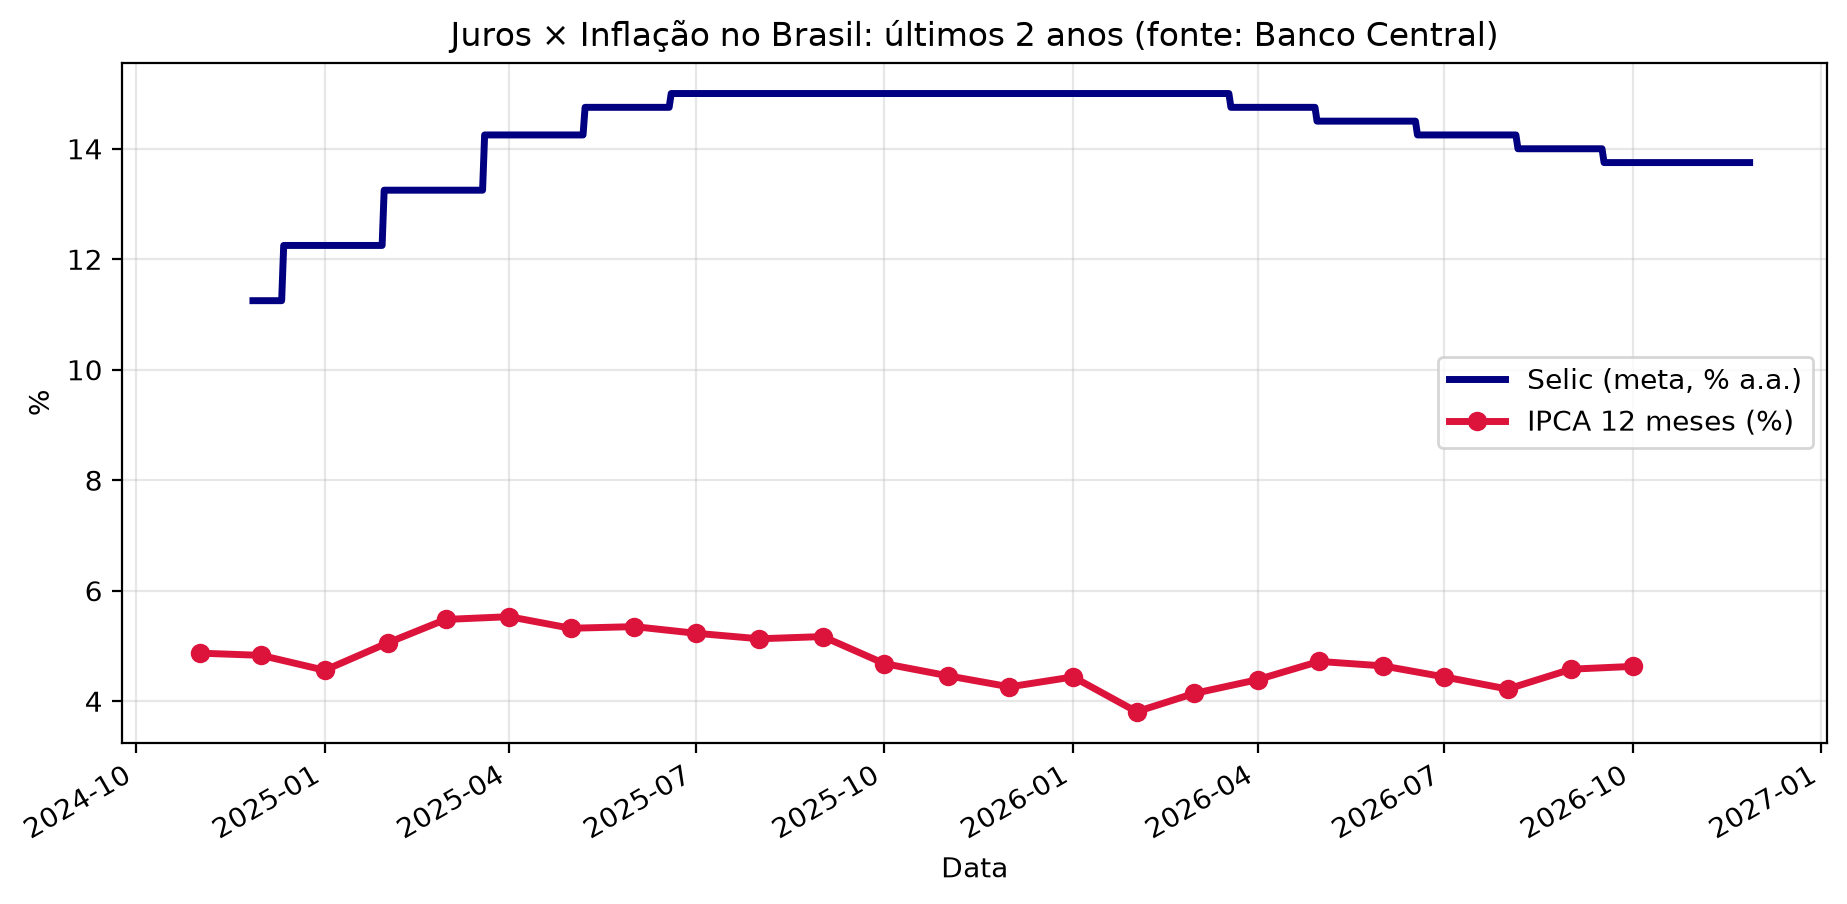

In [8]:
# ============================================================
# PASSO 6 - O GRÁFICO
# ============================================================

# [VARIÁVEL] 2 anos para trás (2 x 365 dias)
inicio_grafico = datetime.now() - timedelta(days=2 * 365)

# [OBJETO] pegamos os objetos da lista e chamamos o [MÉTODO] buscar() com o novo período
selic = indicadores[0]
ipca_12m = indicadores[3]
selic.buscar(data_inicial=inicio_grafico)
ipca_12m.buscar(data_inicial=inicio_grafico)

# [FUNÇÃO] plt.subplots() cria a figura (fig) e a área do gráfico (ax)
fig, ax = plt.subplots(figsize=(11, 5))

# [MÉTODO] ax.plot() desenha cada linha. [ATRIBUTO] .historico é a tabela de cada objeto
ax.plot(selic.historico["data"], selic.historico["valor"],
        color="navy", linewidth=2.5, label="Selic (meta, % a.a.)")

ax.plot(ipca_12m.historico["data"], ipca_12m.historico["valor"],
        color="crimson", linewidth=2.5, marker="o", label="IPCA 12 meses (%)")

# [MÉTODO] títulos, eixos, grade e legenda
ax.set_title(label="Juros × Inflação no Brasil: últimos 2 anos (fonte: Banco Central)")
ax.set_xlabel(xlabel="Data")
ax.set_ylabel(ylabel="%")
ax.grid(visible=True, alpha=0.3)
ax.legend()

# [MÉTODO] inclina as datas do eixo X
fig.autofmt_xdate()

plt.show()

## Passo 7 (bônus): Salvar os resultados

Salvamos o **painel** em `.csv` e o **gráfico** em `.png`, com a data de hoje no nome do arquivo.

In [9]:
# ============================================================
# PASSO 7 - SALVAR PAINEL E GRÁFICO
# ============================================================

linhas_painel = []   # [LISTA] vazia

# [LOOP] monta uma linha da tabela para cada indicador
for indicador in indicadores:
    ultima_linha = indicador.historico.iloc[-1]

    # [MÉTODO] .append() com um [DICIONÁRIO]: cada chave vira uma coluna
    linhas_painel.append({
        "indicador": indicador.nome,        # [ATRIBUTO]
        "codigo_bcb": indicador.codigo,     # [ATRIBUTO]
        "valor": ultima_linha["valor"],
        "unidade": indicador.unidade,       # [ATRIBUTO]
        "data_referencia": ultima_linha["data"].strftime(format="%d/%m/%Y"),
    })

# [OBJETO] DataFrame criado a partir da lista
painel = pd.DataFrame(data=linhas_painel)

hoje = datetime.now().strftime(format="%Y-%m-%d")
nome_csv = f"painel_indicadores_{hoje}.csv"
nome_png = f"grafico_juros_inflacao_{hoje}.png"

# [MÉTODO] salva a tabela e o gráfico
painel.to_csv(path_or_buf=nome_csv, index=False)
fig.savefig(fname=nome_png, dpi=150, bbox_inches="tight")

print("Arquivos salvos na mesma pasta deste notebook:")
print("  📄", nome_csv)
print("  🖼️ ", nome_png)

# mostra a tabela no notebook
painel

Arquivos salvos na mesma pasta deste notebook:
  📄 painel_indicadores_2026-11-27.csv
  🖼️  grafico_juros_inflacao_2026-11-27.png


,indicador,codigo_bcb,valor,unidade,data_referencia
0,Selic (meta),432,13.750,% a.a.,27/11/2026
1,CDI,4389,13.650,% a.a.,26/11/2026
2,IPCA no mês,433,0.140,%,01/10/2026
3,IPCA 12 meses,13522,4.630,%,01/10/2026
4,IGP-M no mês,189,1.240,%,01/11/2026
5,Dólar PTAX,1,5.543,R$,27/11/2026


## Passo 8 (bônus): Salvar o histórico completo

O CSV do Passo 7 é uma **foto do dia**: só tem o valor **mais recente** de cada indicador (por causa do `.iloc[-1]`).
Mas cada objeto guarda **todos** os valores buscados no atributo `historico`. Agora vamos salvar esse histórico completo!

Antes, buscamos todos os indicadores com o **mesmo período** (2 anos). Lembre que, até aqui, só a Selic e o IPCA 12 meses tinham 2 anos; os outros tinham apenas 120 dias.

Vamos montar **uma tabela só**, com uma coluna `indicador` dizendo de qual indicador é cada linha.

> ⏳ Esta célula faz 6 pedidos à API e pode levar alguns segundos.

In [10]:
# ============================================================
# PASSO 8 - SALVAR O HISTÓRICO COMPLETO DE TODOS OS INDICADORES
# ============================================================

tabelas = []   # [LISTA] vazia, que vai guardar uma tabela por indicador

# [LOOP] para cada objeto da lista...
for indicador in indicadores:
    # [MÉTODO] busca de novo, agora com o período do gráfico (2 anos)
    indicador.buscar(data_inicial=inicio_grafico)

    # [MÉTODO] .copy() faz uma cópia da tabela, para não mexer no historico original
    tabela = indicador.historico.copy()

    # Nova coluna: o mesmo texto (nome do indicador) em TODAS as linhas
    tabela["indicador"] = indicador.nome      # [ATRIBUTO]
    tabela["unidade"] = indicador.unidade     # [ATRIBUTO]

    # [MÉTODO] .append() adiciona a tabela no fim da lista
    tabelas.append(tabela)

    # [FUNÇÃO] len() conta quantas linhas (datas) vieram
    print(f"{indicador.nome:<28} {len(tabela):>5} valores")

# [FUNÇÃO] pd.concat() "empilha" as tabelas da lista, uma embaixo da outra
historico_completo = pd.concat(objs=tabelas, ignore_index=True)

# Reorganiza a ordem das colunas: [LISTA] com os nomes na ordem desejada
historico_completo = historico_completo[["indicador", "data", "valor", "unidade"]]

nome_historico = f"historico_indicadores_{hoje}.csv"

# [MÉTODO] salva a tabela. date_format -> datas no formato dia/mês/ano
historico_completo.to_csv(path_or_buf=nome_historico, index=False, date_format="%d/%m/%Y")

print()
print("Arquivo salvo:  📄", nome_historico)
print("Total de linhas:", len(historico_completo))

# mostra as primeiras linhas da tabela
historico_completo.head(n=10)

Selic (meta)                   731 valores
CDI                            501 valores
IPCA no mês                     24 valores
IPCA 12 meses                   24 valores
IGP-M no mês                    25 valores
Dólar PTAX                     502 valores

Arquivo salvo:  📄 historico_indicadores_2026-11-27.csv
Total de linhas: 1807


,indicador,data,valor,unidade
0,Selic (meta),2024-11-27,11.25,% a.a.
1,Selic (meta),2024-11-28,11.25,% a.a.
2,Selic (meta),2024-11-29,11.25,% a.a.
3,Selic (meta),2024-11-30,11.25,% a.a.
4,Selic (meta),2024-12-01,11.25,% a.a.
5,Selic (meta),2024-12-02,11.25,% a.a.
6,Selic (meta),2024-12-03,11.25,% a.a.
7,Selic (meta),2024-12-04,11.25,% a.a.
8,Selic (meta),2024-12-05,11.25,% a.a.
9,Selic (meta),2024-12-06,11.25,% a.a.


## 🎯 Resumo: onde usamos cada conceito

| Conceito | Onde apareceu |
|---|---|
| **Módulo** | `requests`, `pandas`, `matplotlib`, `datetime` (Passo 1) |
| **Lista** | resposta da API (Passo 2) e `indicadores`, uma lista de **objetos** (Passo 5) |
| **Dicionário** | cada item da API, `item["valor"]`, e os `parametros` do pedido (Passo 4) |
| **Loop** | percorrer a resposta (Passos 2 e 4), tentar de novo com `range(3)` + `break` (Passo 4), montar o painel (Passos 5 e 7) e juntar os históricos (Passo 8) |
| **Classe** | `Indicador`, que **guarda** informações **e** busca dados (Passo 4); `timedelta`, do Python, que representa um intervalo de tempo (Passo 1) |
| **Objeto** | `ipca`, cada item de `indicadores` |
| **Atributo** | `self.codigo`, `self.historico`, `indicador.nome` |
| **Método** | `buscar()`, `mostrar()`, `.strftime()`, `.strptime()`, `.append()`, `ax.plot()` |
| **Condicional** | `if resposta.status_code == 200` e `if self.unidade == "R$"` (Passo 4) |
| **Função** | `print()`, `float()`, `len()`, `type()`, `requests.get()`, `pd.concat()` |

### 🆚 Diferença em relação à automação do dólar
- **Dólar:** a classe `Cotacao` só **guardava** dados, e uma **função** separada fazia a busca.
- **Indicadores:** a classe `Indicador` **guarda e busca**, porque a busca virou um **método** do objeto. Os dois jeitos estão certos!

### 🏋️ Desafios para praticar
1. Adicione ao painel a **Selic efetiva** (código `1178`, unidade `"% a.a."`). Coloque o novo indicador no **final** da lista `indicadores`: o juro real (Passo 5.1) e o gráfico (Passo 6) pegam a Selic e o IPCA pela **posição**.
2. Mude o gráfico do Passo 6 para mostrar os últimos **5 anos**.
3. Crie um novo método `variacao()` na classe, que mostre a diferença entre o primeiro e o último valor do `historico`. Lembre: o `historico` só existe depois de chamar `buscar()` (antes disso ele é `None`).

> 🔎 Para encontrar outros códigos de séries, pesquise no site do SGS do Banco Central: https://www3.bcb.gov.br/sgspub